# 01 · Data cleaning and exploratory analysis

**Goal:** understand the data, define the claim target, choose predictors, and document every cleaning decision.

Sections:
1. Load and inspect
2. Understand the variables
3. Define the target
4. Clean and create features
5. Explore claim rates by risk factor
6. Choose predictors and save train/test files

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # make `src` importable from notebooks/

import numpy as np
import pandas as pd
from lets_plot import *

from src import config

LetsPlot.setup_html()

## 1. Load and inspect

In [2]:
from src.data_prep import load_raw
raw = load_raw()
print(raw.shape)
raw.head()

(354140, 47)


,insured_id,year,policy_type,policy_status,business_type,payment_frequency,bonus_score,driver_age,vehicle_age,age_driving_licence,...,liability_property_incurred,liability_injury_incurred,property_incurred,theft_incurred,fire_incurred,glass_incurred,legal_protection_incurred,occupants_incurred,total_exposure,liability_exposure
0,1,2022,COMP_E,C,NB,A,G,48,22.0,26.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.09863,0.09863
1,2,2022,COMP_E,A,P,A,G,43,24.0,19.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
2,2,2023,COMP_E,A,P,A,G,44,25.0,19.0,...,233.013,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
3,2,2024,COMP_E,A,P,A,G,45,26.0,18.0,...,1035.000,0.0,1551.3615,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000
4,3,2022,COMP_E,A,NB,S,G,45,26.0,19.0,...,0.000,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,1.00000,1.00000


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 354140 entries, 0 to 354139
Data columns (total 47 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   insured_id                   354140 non-null  int64  
 1   year                         354140 non-null  int64  
 2   policy_type                  354140 non-null  str    
 3   policy_status                354140 non-null  str    
 4   business_type                354140 non-null  str    
 5   payment_frequency            354140 non-null  str    
 6   bonus_score                  354140 non-null  str    
 7   driver_age                   354140 non-null  int64  
 8   vehicle_age                  354138 non-null  float64
 9   age_driving_licence          354138 non-null  float64
 10  fuel_type                    352853 non-null  str    
 11  vehicle_value                353627 non-null  float64
 12  seats                        354140 non-null  int64  
 13  power_to_w

In [4]:
# Missing values per column
raw.isna().mean().sort_values(ascending=False).head(20)

fuel_type                  0.003634
vehicle_value              0.001449
age_driving_licence        0.000006
vehicle_age                0.000006
insured_id                 0.000000
year                       0.000000
policy_type                0.000000
bonus_score                0.000000
payment_frequency          0.000000
business_type              0.000000
policy_status              0.000000
driver_age                 0.000000
seats                      0.000000
power_to_weight_ratio      0.000000
vehicle_brand              0.000000
municipality_type          0.000000
circulation_area           0.000000
total_premium              0.000000
liability_premium          0.000000
property_damage_premium    0.000000
dtype: float64

## 2. Understand the variables

The file contains policy years **2022, 2023, and 2024** only. Train on 2022–2023 and test on 2024. That 2024 test is the stand-in for “next year.” The app can later apply the same model to a new driver and report a next-year claim probability. There is no 2026 outcome in this file, so 2026 is not the training target.

For each row, a column is a fair predictor only if the insurer would have known it at the **start of that row’s policy year**.

> ⚠️ Only use information available **before** the year you are predicting. Variables recorded after a claim (e.g. claim costs, cancellations caused by claims) would leak the answer.

### How these predictors were chosen

Definitions come from `data/raw/Descriptive of variables.csv`. The 14 columns below are a **candidate list**, chosen before looking at claim rates. A column was included only when both of these were true:

1. The insurer would already know it on the first day of that policy year.
2. It describes the driver, the vehicle, or the contract, so it could plausibly affect claim risk.

No column was kept or dropped because of a chart. The charts in section 5 show which of these facts actually change the claim rate. The list itself is the one now stored in `src/config.py`.

Columns failed the rule for a specific reason:

- `total_claims` and the other `*_claims` and `*_incurred` columns are the outcome for that same year.
- `policy_status` can change during the year, including after a claim.
- Premium columns are the insurer’s current price, so using them would mostly copy the existing rating.
- `insured_id` and `year` only identify the policy and split 2022–2023 from 2024.
- `total_exposure` is how much of the year the policy was in force. It is an offset, not a reason the driver is risky.

### Predictors

Known at the start of the policy year. These describe the driver, the vehicle, and the contract.

| Variable | Meaning | Type |
|---|---|---|
| `driver_age` | Age of the main driver, in years | numeric |
| `vehicle_age` | Age of the insured vehicle, in years | numeric |
| `age_driving_licence` | Years since the driving licence was issued. Values run from 0 to 80 (median 20), so this is a duration, not a calendar year | numeric |
| `vehicle_value` | Declared insured value of the vehicle | numeric |
| `seats` | Number of seats | numeric |
| `power_to_weight_ratio` | Vehicle weight per horsepower, a proxy for performance | numeric |
| `fuel_type` | Diesel (`D`) or gasoline (`G`) | category |
| `vehicle_brand` | Brand of the insured vehicle | category |
| `policy_type` | Coverage package: `TP` third party, `TPG` third party plus glass, `CC` combined cover, `COMP_E` comprehensive with excess, `COMP_N` comprehensive without excess | category |
| `business_type` | `NB` new business or `P` existing portfolio policy | category |
| `payment_frequency` | Billing frequency: `A` annual, `S` semiannual, `Q` quarterly | category |
| `bonus_score` | Past claims history: `G` good, `N` neutral, `B` bad | category |
| `municipality_type` | `I` inland, `C` coastal, `IS` islands | category |
| `circulation_area` | Usual driving area: `U` urban or `R` rural | category |

### Identifiers and model structure

| Variable | Role |
|---|---|
| `insured_id` | Links the same policy across years. Not a predictor. |
| `year` | Used only to split 2022–2023 (train) from 2024 (test). Not a predictor. |
| `total_exposure` | Fraction of the year the policy was in force, from 0 to 1. Used as an offset so a policy covered for part of the year is not treated like a full year. Not a reason the driver is risky. |

### Left out

Same-year claim counts and costs are the outcome. That includes `total_claims` and every `*_claims` and `*_incurred` column.

`policy_status` records whether the policy was still active (`A`) or was cancelled (`C`) during that year. A cancellation can follow a claim, so it is not known at the start of the year.

Premium columns (`total_premium` and each `*_premium`) are the insurer’s existing price. Using them would mostly copy the current rating instead of learning risk from the driver and the vehicle.

## 3. Define the target

**Choice:** all coverages, using `total_claims`.

The question is whether a policy has at least one claim in the year, not a claim under one coverage only. `total_claims` already adds every coverage together. The model target is `claim = 1` when `total_claims > 0`.

About 86% of policy-years have zero claims, and about 14% have one or more (the maximum is 18). The count is mostly zeros, so a yes/no target matches the question better than predicting the exact number of claims.

In [5]:
counts = raw["total_claims"].value_counts().sort_index()
summary = pd.DataFrame({"policies": counts, "share": counts / counts.sum()})
summary.index.name = "total_claims"
print(summary.to_string())
print(f"\nPolicies with at least one claim: {(raw['total_claims'] > 0).mean():.1%}")

by_year = raw.groupby("year").apply(
    lambda d: pd.Series({
        "policies": len(d),
        "at_least_one_claim": (d["total_claims"] > 0).mean(),
    }),
    include_groups=False,
)
print("\nBy policy year")
print(by_year.to_string())



              policies     share
total_claims                    
0               303333  0.856534
1                35810  0.101118
2                 8902  0.025137
3                 3212  0.009070
4                 1455  0.004109
5                  912  0.002575
6                  323  0.000912
7                  112  0.000316
8                   38  0.000107
9                   22  0.000062
10                   8  0.000023
11                   7  0.000020
13                   3  0.000008
14                   1  0.000003
17                   1  0.000003
18                   1  0.000003

Policies with at least one claim: 14.3%



By policy year
      policies  at_least_one_claim
year                              
2022   67172.0            0.129876
2023  118835.0            0.139984
2024  168133.0            0.151356


In [6]:
plot_counts = raw["total_claims"].clip(upper=5).value_counts().sort_index()
plot_df = plot_counts.rename_axis("claims").reset_index(name="policies")
plot_df["claims"] = plot_df["claims"].map(lambda i: str(int(i)) if i < 5 else "5+")

ggplot(plot_df, aes(x="claims", y="policies")) + \
    geom_bar(stat="identity", fill="#4C78A8") + \
    labs(
        x="Number of claims in the policy year",
        y="Policies",
        title="Claim count distribution, all coverages",
    ) + \
    ggsize(700, 400)

## 4. Clean the rows

Cleaning lives in `src/data_prep.py`. `clean()` drops a row the model cannot use: no time on cover, a missing age or vehicle value, a driver under 16, a negative age, or a weight-per-horsepower of 0 or below. A missing fuel type is kept as its own group, `Unknown`. That leaves 353,573 of 354,140 rows.

No new columns are calculated. The ages, the licence duration, and the vehicle facts are already in the file. Two adjustments happen later, inside `main()`, and they are learned on 2022–2023 only so 2024 does not help choose them:

- Vehicle value is capped at the training 99th percentile (about 71,122).
- Brands with fewer than 1,000 training policies are grouped into `Other`.

In [7]:
import importlib
importlib.reload(config)

from src.data_prep import clean, make_target
df = make_target(clean(raw))
df.shape

Clean: kept 353,573 of 354,140 rows


(353573, 48)

## 5. Explore claim rates by risk factor

Use **exposure-weighted** claim rates: total claims ÷ total exposure per group. A simple mean of the 0/1 target ignores that some policies were only insured for part of the year.


driver_age
                policies   exposure  claims  claims_per_exposure_year
driver_age                                                           
(17.999, 25.0]      1771   1150.225     364                     0.316
(25.0, 35.0]       48733  33841.822    8023                     0.237
(35.0, 45.0]      102955  72699.247   15291                     0.210
(45.0, 55.0]       87957  62146.093   12482                     0.201
(55.0, 65.0]       74109  53216.099    9990                     0.188
(65.0, 100.0]      38048  26925.148    4598                     0.171

vehicle_age
               policies    exposure  claims  claims_per_exposure_year
vehicle_age                                                          
(-0.001, 5.0]      6729    4323.268    1335                     0.309
(5.0, 10.0]       25113   17132.795    4079                     0.238
(10.0, 15.0]      41597   29085.655    6534                     0.225
(15.0, 20.0]      54820   38958.058    8231                     0

                       policies    exposure  claims  claims_per_exposure_year
power_to_weight_ratio                                                        
(-0.001, 8.0]              8809    6253.055    1454                     0.233
(8.0, 12.0]              167189  119304.129   25534                     0.214
(12.0, 16.0]             150469  105741.981   20457                     0.193
(16.0, 25.0]              27018   18615.142    3294                     0.177
(25.0, 80.0]                 88      64.326       9                     0.140

bonus_score
             policies    exposure  claims  claims_per_exposure_year
bonus_score                                                        
G              341019  242034.926   48335                     0.200
N                7837    4872.208    1376                     0.282
B                4717    3071.499    1037                     0.338

policy_type
             policies    exposure  claims  claims_per_exposure_year
policy_type         

                   policies    exposure  claims  claims_per_exposure_year
municipality_type                                                        
IS                    24035   17305.792    3101                     0.179
C                    101213   71810.137   13782                     0.192
I                    228325  160862.704   33865                     0.211

circulation_area
                  policies    exposure  claims  claims_per_exposure_year
circulation_area                                                        
R                   163346  114705.652   21876                     0.191
U                   190227  135272.981   28872                     0.213

seats
       policies    exposure  claims  claims_per_exposure_year
seats                                                        
2          4224    2922.340     514                     0.176
4         16304   11544.425    2215                     0.192
5        300429  212481.195   42674                     0.201
7  

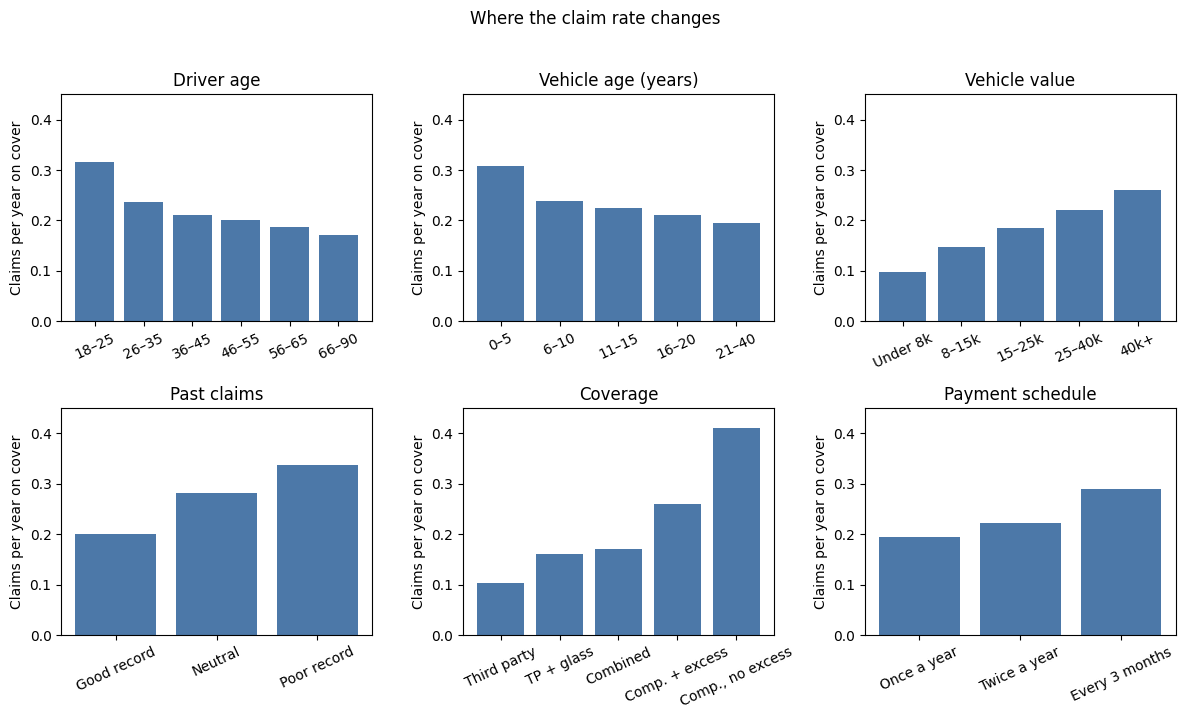

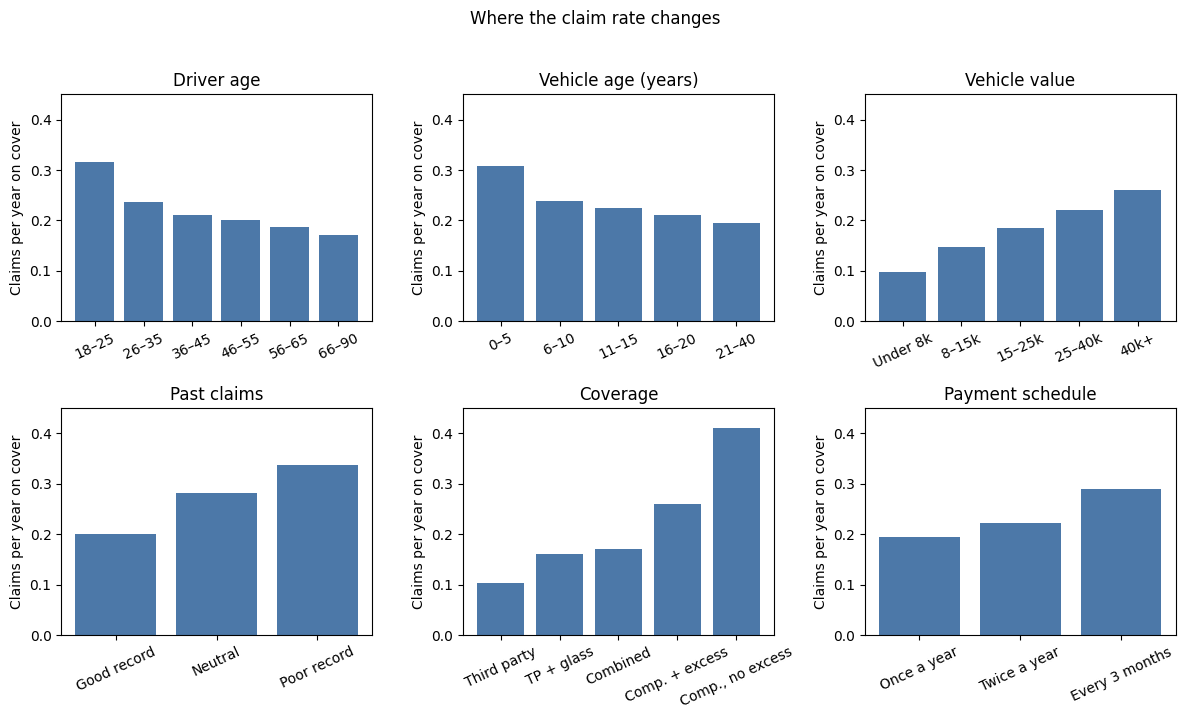

In [8]:
import matplotlib.pyplot as plt

def claim_rate_by(df, col, bins=None):
    g = df[col] if bins is None else pd.cut(df[col], bins, include_lowest=True)
    out = df.groupby(g, observed=True).agg(
        policies=(config.TARGET, "size"),
        exposure=(config.EXPOSURE_COL, "sum"),
        claims=(config.TARGET, "sum"),
    )
    out["claims_per_exposure_year"] = out["claims"] / out["exposure"]
    return out

numeric_bins = {
    "driver_age": [18, 25, 35, 45, 55, 65, 100],
    "vehicle_age": [0, 5, 10, 15, 20, 40],
    "age_driving_licence": [0, 10, 20, 40, 80],
    "vehicle_value": [0, 8000, 15000, 25000, 40000, 200000],
    "power_to_weight_ratio": [0, 8, 12, 16, 25, 80],
}
categories = [
    "bonus_score", "policy_type", "payment_frequency", "fuel_type",
    "business_type", "municipality_type", "circulation_area", "seats",
]

for col, bins in numeric_bins.items():
    print(f"\n{col}")
    print(claim_rate_by(df, col, bins).round(3).to_string())
for col in categories:
    print(f"\n{col}")
    print(claim_rate_by(df, col).sort_values("claims_per_exposure_year").round(3).to_string())
brands = claim_rate_by(df, "vehicle_brand")
brands = brands[brands["policies"] >= 1000].sort_values("claims_per_exposure_year")
print("\nvehicle_brand, brands with at least 1,000 policies")
print(brands.round(3).to_string())

titles = {
    "driver_age": "Driver age",
    "vehicle_age": "Vehicle age (years)",
    "vehicle_value": "Vehicle value",
    "bonus_score": "Past claims",
    "policy_type": "Coverage",
    "payment_frequency": "Payment schedule",
}
cat_names = {
    "bonus_score": {"G": "Good record", "N": "Neutral", "B": "Poor record"},
    "policy_type": {
        "TP": "Third party", "TPG": "TP + glass", "CC": "Combined",
        "COMP_E": "Comp. + excess", "COMP_N": "Comp., no excess",
    },
    "payment_frequency": {"A": "Once a year", "S": "Twice a year", "Q": "Every 3 months"},
}
cat_order = {
    "bonus_score": ["Good record", "Neutral", "Poor record"],
    "policy_type": ["Third party", "TP + glass", "Combined", "Comp. + excess", "Comp., no excess"],
    "payment_frequency": ["Once a year", "Twice a year", "Every 3 months"],
}
bin_names = {
    "driver_age": ["18\u201325", "26\u201335", "36\u201345", "46\u201355", "56\u201365", "66\u201390"],
    "vehicle_age": ["0\u20135", "6\u201310", "11\u201315", "16\u201320", "21\u201340"],
    "vehicle_value": ["Under 8k", "8\u201315k", "15\u201325k", "25\u201340k", "40k+"],
}

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.ravel(), titles):
    if col in bin_names:
        grouped = pd.cut(df[col], numeric_bins[col], include_lowest=True)
        table = df.groupby(grouped, observed=True).agg(
            claims=(config.TARGET, "sum"), exposure=(config.EXPOSURE_COL, "sum")
        )
        table["claims_per_exposure_year"] = table["claims"] / table["exposure"]
        groups = bin_names[col]
        rates = table["claims_per_exposure_year"].to_numpy()
    else:
        table = claim_rate_by(df, col).reset_index()
        table["group"] = table[col].map(cat_names[col])
        table["_ord"] = table["group"].map({name: i for i, name in enumerate(cat_order[col])})
        table = table.sort_values("_ord")
        groups = table["group"]
        rates = table["claims_per_exposure_year"]
    ax.bar(groups, rates, color="#4C78A8")
    ax.set_title(titles[col])
    ax.set_ylabel("Claims per year on cover")
    ax.tick_params(axis="x", labelrotation=25)
    ax.set_ylim(0, 0.45)
fig.suptitle("Where the claim rate changes", y=1.02)
fig.tight_layout()
fig_path = Path("..") / "reports" / "figures" / "claim_rates.png"
fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_path, dpi=150, bbox_inches="tight")
fig

**Observations:**

The rate is claims divided by years on cover, so a policy that lasted half a year counts as half a policy.

- **Driver age.** The file has no driver under 18. Drivers 18–25 claim about 32 times per 100 years on cover. Drivers over 65 claim about 17 times. The rate falls steadily as age rises, which is the usual young-driver pattern.
- **Vehicle age.** Cars under 5 years claim about 31 times per 100 years on cover. Cars over 20 years claim about 19 times. Newer cars claim more often.
- **Vehicle value.** From about 8,000 to 15,000 the rate is 15 per 100 years on cover. Above 40,000 it is 26. More expensive cars claim more often. The under-8,000 group is only 788 policies, so that low rate is a thin group.
- **Past claims.** A good record claims about 20 times per 100 years on cover, a neutral record about 28, and a poor record about 34. That matches the meaning of the score. About 96% of policies are already in the good group, so the score splits only a few policies.
- **Coverage.** Third party only is about 10 per 100 years on cover. Combined cover is about 17. Comprehensive cover with no excess is about 41. Broader cover goes with more claims, partly because that cover pays for more kinds of damage.
- **Payment.** Paying once a year is about 20, twice a year about 22, and every three months about 29. Paying more often goes with a higher claim rate. That is a clue about the customer, not proof that the payment plan causes a claim.

A few candidates barely move. A new policy and an existing policy are almost the same (20.2 and 20.4). Town is 21 and country is 19. Inland is 21, the coast 19, and islands 18. Years with a licence sit mostly between 10 and 40, and both of those groups claim about 20 times per 100 years on cover. Among brands with at least 1,000 policies, the rate runs from about 13 (Rover) to about 27 (BMW).

## 6. Choose predictors and save

The day-one list in section 2 is the list in `src/config.py`. Every one of those columns is kept. A tree can ignore a column that barely moves the rate, such as new versus existing policy. Premiums, claim counts, claim costs, and `policy_status` stay out.

`main()` writes the training file (2022–2023) and the test file (2024). It also caps vehicle value and groups rare brands, using the training years only.

In [9]:
from src.data_prep import main
main()

Raw data: 354,140 rows, 47 columns


Clean: kept 353,573 of 354,140 rows


Vehicle value capped at 71,122


Vehicle brands kept: 24 common, the rest grouped as Other
Train: 185,720 rows | claim rate 13.64%
Test:  167,853 rows | claim rate 15.14%


Saved to C:\Users\angek\OneDrive\Others\Bureau\Senior-Project\predictNextClaim\data\processed
